# 00 · Environment, Reproducibility and Course Map

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/00-environment/00_environment.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-00-environment.yml)

| | |
|---|---|
| **Wiki chapter** | [Notebook roadmap](https://github.com/anuxlab/deep-learning-systems/wiki/Notebook-Roadmap) |
| **Level** | Foundational |
| **Typical CPU runtime** | < 1 min (GitHub free runner, no GPU) |
| **Prerequisites** | none |

## What you will do

- Record the exact software/hardware environment of a run (the *reproducibility record*).
- Verify that seeding makes NumPy and PyTorch results repeatable on the same machine.
- Measure what a free CPU runner can do, so you can size later experiments.
- See how the 24 wiki modules map to practical notebooks and CI workflows.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

12:48:39 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.4
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 42818770537
          commit: 61c9ecbc3039f19fc5c99df211fed2184186b3ae


## 1 · Seeds make randomness repeatable
Pseudo-random generators are deterministic functions of their *seed*. If two runs start from the same seed and perform the same operations, they produce the same numbers. This is the foundation of a reproducible experiment. Caveat from the wiki standards: a fixed seed does **not** guarantee bit-identical results across *different* devices or library versions — so we also record versions.

In [2]:
def draw(seed):
    seed_everything(seed)
    a = np.random.randn(3)
    b = torch.randn(3).numpy()
    return a, b

a1, b1 = draw(0); a2, b2 = draw(0); a3, b3 = draw(1)
print("numpy  run1:", a1); print("numpy  run2:", a2)
print("torch  run1:", b1); print("torch  run2:", b2)
check(np.array_equal(a1, a2) and np.array_equal(b1, b2), "same seed -> identical NumPy and PyTorch draws")
check(not np.array_equal(a1, a3), "different seed -> different draws")

12:48:40 | INFO | seed set to 0


12:48:40 | INFO | seed set to 0


12:48:40 | INFO | seed set to 1


numpy  run1: [1.76405235 0.40015721 0.97873798]
numpy  run2: [1.76405235 0.40015721 0.97873798]
torch  run1: [ 1.5409961 -0.2934289 -2.1787894]
torch  run2: [ 1.5409961 -0.2934289 -2.1787894]
  ✅ same seed -> identical NumPy and PyTorch draws
  ✅ different seed -> different draws


## 2 · What can a free GitHub runner do?
A standard public-repo `ubuntu-latest` runner has **4 vCPUs, ~16 GB RAM and no GPU**. We time dense matrix multiplication (the workhorse of deep learning) to estimate throughput. For an $n\times n$ product the cost is $2n^3$ floating-point operations, so

$$\text{GFLOP/s} = \frac{2n^3}{t\cdot 10^9}.$$

This number tells you how large a model you can reasonably train in a few minutes.

n=   64  numpy    49.5 GFLOP/s   torch     0.5 GFLOP/s
n=  128  numpy     1.4 GFLOP/s   torch     0.3 GFLOP/s


n=  256  numpy    16.3 GFLOP/s   torch     1.8 GFLOP/s


n=  512  numpy   202.4 GFLOP/s   torch    25.4 GFLOP/s


n= 1024  numpy   212.2 GFLOP/s   torch    94.2 GFLOP/s


n= 1536  numpy   219.3 GFLOP/s   torch   141.2 GFLOP/s
12:48:41 | INFO | figure saved -> figures/matmul_throughput.png


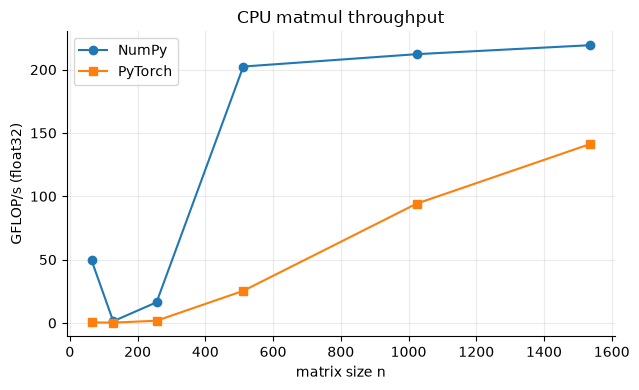

  ✅ matmul benchmark produced a sane throughput


In [3]:
import time
sizes = [64, 128, 256, 512, 1024, 1536]
gflops_np, gflops_t = [], []
for n in sizes:
    A = np.random.randn(n, n).astype(np.float32); B = np.random.randn(n, n).astype(np.float32)
    reps = 5
    t0 = time.perf_counter()
    for _ in range(reps): A @ B
    t = (time.perf_counter() - t0) / reps
    gflops_np.append(2 * n**3 / t / 1e9)
    At, Bt = torch.from_numpy(A), torch.from_numpy(B)
    t0 = time.perf_counter()
    for _ in range(reps): At @ Bt
    t = (time.perf_counter() - t0) / reps
    gflops_t.append(2 * n**3 / t / 1e9)
    print(f"n={n:5d}  numpy {gflops_np[-1]:7.1f} GFLOP/s   torch {gflops_t[-1]:7.1f} GFLOP/s")

plt.plot(sizes, gflops_np, "o-", label="NumPy"); plt.plot(sizes, gflops_t, "s-", label="PyTorch")
plt.xlabel("matrix size n"); plt.ylabel("GFLOP/s (float32)"); plt.title("CPU matmul throughput"); plt.legend()
show("matmul_throughput")
METRICS["peak_gflops_numpy"] = max(gflops_np); METRICS["peak_gflops_torch"] = max(gflops_t)
check(max(gflops_np) > 0.1, "matmul benchmark produced a sane throughput")

## 3 · Memory and parameter budgeting
Before training anything, estimate memory: float32 uses 4 bytes per number. A model with $P$ parameters trained with Adam stores weights + gradients + two moment buffers $\approx 16P$ bytes (plus activations).

In [4]:
def adam_train_bytes(P): return 16 * P
for name, P in [("tiny MLP (50k)", 5e4), ("small CNN (1M)", 1e6), ("tiny GPT (10M)", 1e7), ("GPT-2 small (124M)", 1.24e8), ("7B LLM", 7e9)]:
    print(f"{name:22s} params={P:12,.0f}  Adam training state ≈ {adam_train_bytes(P)/2**30:9.3f} GiB")
check(adam_train_bytes(1.24e8) / 2**30 < 16, "GPT-2-small weights+Adam state fit in a 16 GB runner (activations aside)")
check(adam_train_bytes(7e9) / 2**30 > 16, "a 7B model does NOT fit -> why we use tiny models in CI")

tiny MLP (50k)         params=      50,000  Adam training state ≈     0.001 GiB
small CNN (1M)         params=   1,000,000  Adam training state ≈     0.015 GiB
tiny GPT (10M)         params=  10,000,000  Adam training state ≈     0.149 GiB
GPT-2 small (124M)     params= 124,000,000  Adam training state ≈     1.848 GiB
7B LLM                 params=7,000,000,000  Adam training state ≈   104.308 GiB
  ✅ GPT-2-small weights+Adam state fit in a 16 GB runner (activations aside)
  ✅ a 7B model does NOT fit -> why we use tiny models in CI


## 4 · Course map: module → notebook → workflow
Each notebook has its own **manually-triggered GitHub Actions workflow** (`.github/workflows/nb-<id>-<slug>.yml`). It executes the notebook on a free runner, then commits the executed notebook, HTML, log and figures back into the notebook's folder.

In [5]:
import pandas as pd
rows = [
 ("00","Environment & reproducibility","—"),("01","Linear algebra & tensors","Part 1"),("02","Calculus & autodiff","Part 1"),
 ("03","Probability & information theory","Part 1"),("04","Neurons & perceptrons","Part 2"),("05","Activations & expressivity","Part 2"),
 ("06","Losses & gradient descent","Part 2"),("07","MLPs & backpropagation","Part 2"),("08","Optimisation & loss landscapes","Part 3"),
 ("09","Initialisation & normalisation","Part 3"),("10","Regularisation & generalisation","Part 3"),("11","Convolutional networks","Part 4"),
 ("12","RNN, LSTM, GRU","Part 4"),("13","Seq2seq & attention","Part 4"),("14","Transformers","Part 4"),("15","Positional encoding","Part 4"),
 ("16","Autoencoders","Part 5"),("17","Self-supervised & contrastive","Part 5"),("18","VAEs","Part 5"),("19","GANs","Part 5"),
 ("20","Diffusion models","Part 5"),("21","Graph neural networks","Part 6"),("22","Transfer & foundation models","Part 6"),
 ("23","LLMs & multimodal","Part 6"),("24","Evaluation, robustness, efficiency","Part 6")]
df = pd.DataFrame(rows, columns=["notebook", "topic", "part"])
print(df.to_string(index=False))
check(len(df) == 25, "25 notebooks: environment + 24 wiki modules")

notebook                              topic   part
      00      Environment & reproducibility      —
      01           Linear algebra & tensors Part 1
      02                Calculus & autodiff Part 1
      03   Probability & information theory Part 1
      04              Neurons & perceptrons Part 2
      05         Activations & expressivity Part 2
      06          Losses & gradient descent Part 2
      07             MLPs & backpropagation Part 2
      08     Optimisation & loss landscapes Part 3
      09     Initialisation & normalisation Part 3
      10    Regularisation & generalisation Part 3
      11             Convolutional networks Part 4
      12                     RNN, LSTM, GRU Part 4
      13                Seq2seq & attention Part 4
      14                       Transformers Part 4
      15                Positional encoding Part 4
      16                       Autoencoders Part 5
      17      Self-supervised & contrastive Part 5
      18                       

In [6]:
save_metrics("00", METRICS)
log.info('notebook 00 finished OK')

12:48:41 | INFO | metrics saved -> metrics.json


12:48:41 | INFO | notebook 00 finished OK


## Wrap-up

## Exercises (do these next)

1. Re-run section 2 after setting `torch.set_num_threads(1)`; how does throughput scale?
2. Add a float64 line to the benchmark; what is the float32/float64 ratio and why?

## Where to read more

- Wiki chapter: [Notebook roadmap](https://github.com/anuxlab/deep-learning-systems/wiki/Notebook-Roadmap) (derivations, worked example, Q&A).
